# Gaussian mixture model selection with BIC and GridSearchCV: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/mixture/plot_gmm_selection.py`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/mixture/plot_gmm_selection.html))
at scikit-learn `4358542a1bd39af2e7e1cbace8b9fed067473c5b`.

**Scenario:** 1000 points from a general and a spherical 2-D Gaussian (`np.random.seed(0)`).
`GridSearchCV(GaussianMixture(), {"n_components": 1..6, "covariance_type": [spherical, tied, diag, full]},
scoring=gmm_bic_score)` with the default 5-fold `KFold`, where `gmm_bic_score(estimator, X) = -estimator.bic(X)`
on the held-out fold; then `best_params_`, `best_estimator_.means_/covariances_` and `grid_search.predict(X)`.

**Beyond the gallery:** `aic`, `score`, `score_samples`, `predict_proba` and `sample` of the selected model,
a Float32 fit of the selected configuration, keyword `set_params` + refit, and a `Pipeline` composition check.

**Adaptations:**
- The official `GaussianMixture()` has `random_state=None`, so its KMeans initialization is unseeded and
  the reference is **not deterministic**. The official code runs unchanged for the plot; the parity run uses
  the same search with `GaussianMixture(random_state=0)` on both sides (Moxie with an unseeded estimator
  draws from an entropy stream, which cannot be compared numerically).
- Moxie's `GridSearchCV` takes a typed adapter and scorer instead of a callable (`#3 part 3`): the scorer
  below returns `-estimator.bic(X)` exactly like `gmm_bic_score`, and the adapter passes an ignored
  all-zero target because Moxie search adapters are supervised-shaped. Grid values are `String`s
  (`n_components` is parsed) because one typed value domain must hold both parameters.
- `pandas`/`seaborn` plotting is replaced by a matplotlib bar chart of the same `mean_test_score`s.

**Determinism:** the seeded variant is deterministic; all 24 candidates' fold scores, ranks, the selected
parameters, the refitted learned state and the labels are compared numerically.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("mixture/plot_gmm_selection")

## 1. scikit-learn (Python reference)

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Ellipse
from scipy import linalg

from sklearn.mixture import GaussianMixture
from sklearn.model_selection import GridSearchCV

n_samples = 500
np.random.seed(0)
C = np.array([[0.0, -0.1], [1.7, 0.4]])
component_1 = np.dot(np.random.randn(n_samples, 2), C)  # general
component_2 = 0.7 * np.random.randn(n_samples, 2) + np.array([-4, 1])  # spherical
X = np.concatenate([component_1, component_2])


def gmm_bic_score(estimator, X):
    """Callable to pass to GridSearchCV that will use the BIC score."""
    return -estimator.bic(X)


param_grid = {
    "n_components": range(1, 7),
    "covariance_type": ["spherical", "tied", "diag", "full"],
}
grid_search = GridSearchCV(GaussianMixture(), param_grid=param_grid, scoring=gmm_bic_score)
grid_search.fit(X)
print("official (unseeded) best_params_:", grid_search.best_params_)

# Seeded variant used for parity.
seeded = GridSearchCV(GaussianMixture(random_state=0), param_grid=param_grid, scoring=gmm_bic_score)
seeded.fit(X)
best = seeded.best_estimator_
print("seeded best_params_:", seeded.best_params_, "best_score_:", seeded.best_score_)
sk_params = [f"{p['covariance_type']}/{p['n_components']}" for p in seeded.cv_results_["params"]]
sk_folds = np.array([seeded.cv_results_[f"split{k}_test_score"] for k in range(5)]).T
Y_ = seeded.predict(X)
T = X[::5] + 0.1
sk_extra = dict(aic=best.aic(T), bic=best.bic(T), score=best.score(T), score_samples=best.score_samples(T),
                proba=best.predict_proba(T))
sk_points, sk_labels = best.sample(200)
best32 = GaussianMixture(**seeded.best_params_, random_state=0).fit(X.astype(np.float32))
refit = GaussianMixture(random_state=0).set_params(n_components=3, covariance_type="diag").fit(X)
nb.share(X=X, T=T)

official (unseeded) best_params_: {'covariance_type': 'full', 'n_components': 2}


seeded best_params_: {'covariance_type': 'full', 'n_components': 2} best_score_: -1046.8306296290837


## 2. Moxie (native Mojo)

`GridSearchCV` over the same 24 candidates with a `-bic` scorer and the default unshuffled 5-fold `KFold`.

In [3]:
%%mojo gmm_selection
from numojo import NDArray, Shape
from moxie.mixture import GaussianMixture
from moxie.model_selection import GridSearchCV, KFold, IndexArray, IndexSplit, SearchAdapter, SearchScorer
from moxie.model_selection._split import _rows
from moxie_nb_io import load, save, save_floats, save_strings

comptime Dense = NDArray[DType.float64]
comptime GMM = GaussianMixture[DType.float64]


def kfold(n: Int) raises -> List[IndexSplit]:
    var cursor = KFold(5).split(n)
    var out = List[IndexSplit]()
    while True:
        var pair = cursor.next()
        if not pair:
            break
        out.append(pair.value().copy())
    return out^


struct NegativeBIC(SearchScorer):
    # gmm_bic_score(estimator, X) = -estimator.bic(X) on the held-out fold.
    comptime Estimator = GMM
    comptime Input = Dense
    comptime Target = Dense
    comptime Metadata = Optional[Dense]

    def __init__(out self):
        pass

    def score(self, estimator: GMM, X: Dense, y: Dense, metadata: Optional[Dense]) raises -> Float64:
        return -estimator.bic(X)


struct MixtureSearch(SearchAdapter):
    comptime Scorer = NegativeBIC
    comptime Value = String

    def __init__(out self):
        pass

    def n_samples(self, X: Dense, y: Dense) raises -> Int:
        return X.shape[0]

    def input_rows(self, X: Dense, rows: IndexArray, train: IndexArray) raises -> Dense:
        return _rows(X, rows)

    def target_rows(self, y: Dense, rows: IndexArray) raises -> Dense:
        return _rows(y, rows)

    def metadata_rows(self, metadata: Optional[Dense], rows: IndexArray) raises -> Optional[Dense]:
        return None

    def fit(self, mut estimator: GMM, X: Dense, y: Dense, metadata: Optional[Dense]) raises:
        _ = estimator.fit(X)

    def configure(self, mut estimator: GMM, params: Dict[String, String]) raises:
        for key in params.keys():
            if key == "n_components":
                _ = estimator.set_params(n_components=Int(params[key]))
            elif key == "covariance_type":
                _ = estimator.set_params(covariance_type=params[key])
            else:
                raise Error("ValueError: unknown GaussianMixture parameter " + key)

    def default_scorer(self) raises -> NegativeBIC:
        return NegativeBIC()

    def default_cv(self, X: Dense, y: Dense) raises -> List[IndexSplit]:
        return kfold(X.shape[0])


def main() raises:
    var X = load("X")
    var T = load("T")
    var grid = Dict[String, List[String]]()
    grid["n_components"] = ["1", "2", "3", "4", "5", "6"]
    grid["covariance_type"] = ["spherical", "tied", "diag", "full"]
    var ignored = NDArray[DType.float64](Shape(X.shape[0]))
    for i in range(X.shape[0]):
        ignored.unsafe_set(i, 0)
    var search = GridSearchCV[MixtureSearch](GMM(random_state=0), grid, MixtureSearch(), cv=kfold(X.shape[0]))
    search.fit(X, ignored, None, None)
    var results = search.cv_results_()
    var labels = List[String]()
    for i in range(len(results.params)):
        labels.append(results.params[i]["covariance_type"] + "/" + results.params[i]["n_components"])
    save_strings("params", labels)
    save("mean_test_score", results.mean_test_score)
    save("std_test_score", results.std_test_score)
    save("rank_test_score", results.rank_test_score)
    save("fold_scores", results.scores.test_scores)  # (candidate, split, metric)
    var best_params = search.best_params_()
    save_strings("best_params", [best_params["covariance_type"], best_params["n_components"]])
    save_floats("best_score", [search.best_score_()])
    save("predict", search.predict(X))
    ref best = search.best_estimator_()
    save("means", best.means_)
    save("covariances", best.covariances_)
    save("weights", best.weights_)
    save_floats("aic", [best.aic(T)])
    save_floats("bic", [best.bic(T)])
    save_floats("score", [best.score(T)])
    save("score_samples", best.score_samples(T))
    save("proba", best.predict_proba(T))
    var drawn = best.sample(200)
    save("sample_points", drawn[0])
    save("sample_labels", drawn[1])
    # Float32 fit of the selected configuration.
    var X32 = load[DType.float32]("X")
    var best32 = GaussianMixture[DType.float32](Int(best_params["n_components"]),
        covariance_type=best_params["covariance_type"], random_state=0)
    _ = best32.fit(X32)
    save("means32", best32.means_)
    save("predict32", best32.predict(X32))
    # Keyword set_params then refit.
    var refit = GMM(random_state=0)
    _ = refit.set_params(n_components=3, covariance_type="diag").fit(X)
    save("refit_means", refit.means_)
    print("best_params_:", best_params["covariance_type"], best_params["n_components"], "best_score_:", search.best_score_())

best_params_: full 2 best_score_: -1046.8306296290837


## 3. Side by side and parity

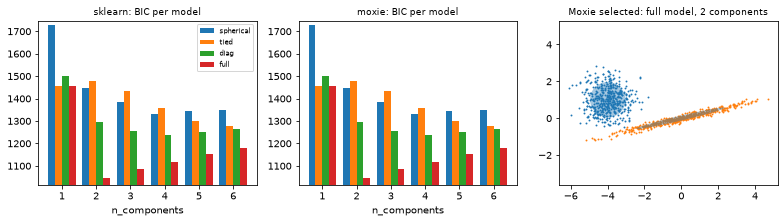

In [4]:
mx = dict(nb.results["gmm_selection"])
# Moxie's SearchResults keep a metric axis: (candidate, metric) and (candidate, split, metric).
for key in ("mean_test_score", "std_test_score", "rank_test_score"):
    mx[key] = mx[key][:, 0]
mx["fold_scores"] = mx["fold_scores"][:, :, 0]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), dpi=72)
types = param_grid["covariance_type"]
width = 0.2
for side, (label, scores) in enumerate([("sklearn", -seeded.cv_results_["mean_test_score"]),
                                        ("moxie", -mx["mean_test_score"])]):
    ax = axes[side]
    for t, cov in enumerate(types):
        idx = [i for i, p in enumerate(sk_params) if p.startswith(cov + "/")]
        ax.bar(np.arange(1, 7) + (t - 1.5) * width, scores[idx], width, label=cov)
    ax.set_title(f"{label}: BIC per model", fontsize=9); ax.set_xlabel("n_components")
    ax.set_ylim(scores.min() * 0.97, scores.max() * 1.01)
axes[0].legend(fontsize=7)
ax = axes[2]
for i, (mean, cov) in enumerate(zip(mx["means"], mx["covariances"])):
    v, w = linalg.eigh(cov)
    ax.scatter(X[mx["predict"] == i, 0], X[mx["predict"] == i, 1], 0.8)
    angle = 180.0 * np.arctan2(w[0][1], w[0][0]) / np.pi
    v = 2.0 * np.sqrt(2.0) * np.sqrt(v)
    ell = Ellipse(mean, v[0], v[1], angle=180.0 + angle, alpha=0.4); ax.add_artist(ell)
ax.set_title(f"Moxie selected: {mx['best_params'][0]} model, {mx['best_params'][1]} components", fontsize=9)
ax.axis("equal")
plt.tight_layout(); plt.show()

moxie_nb.side_by_side(sklearn=np.array(seeded.cv_results_["mean_test_score"]).reshape(4, 6),
                      moxie=np.array(mx["mean_test_score"]).reshape(4, 6))

nb.compare("cv_results_ params order", np.array(sk_params), mx["params"], exact=True)
nb.compare("per-fold -BIC test scores", sk_folds, mx["fold_scores"], rtol=1e-9, atol=1e-9,
           reason="Float64 EM per fold from the same seeded KMeans start; BIC multiplies the mean log-likelihood "
                  "by n (~200), so 1e-12 relative likelihood agreement becomes ~1e-10 here")
nb.compare("mean_test_score", seeded.cv_results_["mean_test_score"], mx["mean_test_score"], rtol=1e-9, reason="as above")
nb.compare("std_test_score", seeded.cv_results_["std_test_score"], mx["std_test_score"], rtol=1e-6, atol=1e-8,
           reason="standard deviation of nearly equal BIC values cancels digits")
nb.compare("rank_test_score", seeded.cv_results_["rank_test_score"], mx["rank_test_score"], exact=True)
nb.compare("best_params_", np.array([seeded.best_params_["covariance_type"], str(seeded.best_params_["n_components"])]),
           mx["best_params"], exact=True)
nb.compare("best_score_", seeded.best_score_, mx["best_score"][0], rtol=1e-9, reason="as above")
nb.compare("best_estimator_.means_", best.means_, mx["means"], rtol=1e-9, atol=1e-11, reason="Float64 refit on all rows")
nb.compare("best_estimator_.covariances_", best.covariances_, mx["covariances"], rtol=1e-8, atol=1e-11,
           reason="second moments; summation order")
nb.compare("best_estimator_.weights_", best.weights_, mx["weights"], rtol=1e-9, atol=1e-12, reason="Float64 refit")
nb.compare("grid_search.predict(X)", Y_, mx["predict"], exact=True)
for key in ("aic", "bic", "score"):
    nb.compare(f"best.{key}(T)", sk_extra[key], mx[key][0], rtol=1e-10, reason="closed-form from the matched fit")
nb.compare("best.score_samples(T)", sk_extra["score_samples"], mx["score_samples"], rtol=1e-9, atol=1e-11,
           reason="log densities of the matched fit")
nb.compare("best.predict_proba(T)", sk_extra["proba"], mx["proba"], rtol=1e-8, atol=1e-12,
           reason="exp of normalized log densities of the matched fit")
nb.compare("best.sample(200) labels", sk_labels, mx["sample_labels"], exact=True)
def norms(points, labels, est):
    d = points - est.means_[labels]
    prec = np.linalg.inv(est.covariances_)[labels]
    return np.einsum("ni,nij,nj->n", d, prec, d)
nb.compare("best.sample(200) Mahalanobis norms", norms(sk_points, sk_labels, best),
           norms(mx["sample_points"], mx["sample_labels"].astype(int), best), rtol=1e-6, atol=1e-9,
           reason="same normal draws through a different square-root factor (SVD orientation, documented)")
nb.compare("Float32 means_", best32.means_, mx["means32"], rtol=5e-4, atol=1e-3,
           reason="Float32 storage with Float64 accumulation in Moxie vs NumPy float32 reductions (pinned parity tolerance)")
nb.compare("Float32 predict", best32.predict(X.astype(np.float32)), mx["predict32"], exact=True)
nb.compare("set_params(n_components=3, covariance_type='diag') refit means_", refit.means_, mx["refit_means"],
           rtol=1e-9, atol=1e-11, reason="Float64 fit")
nb.note("unseeded official search", "ADAPTED",
        "GaussianMixture() without random_state is nondeterministic on both sides; parity uses random_state=0. "
        f"Official run selected {grid_search.best_params_}")
nb.note("cv_results_ metric axis", "ADAPTED",
        "Moxie's mean/std/rank_test_score are (candidates, metrics) and split scores (candidates, splits, metrics)")
nb.note("callable scoring / implicit cv", "ADAPTED",
        "typed SearchScorer + SearchAdapter replace scoring=callable and cv=None (#3 part 3); folds are KFold(5)")

### Composition: a mixture as the final step of a Pipeline

`make_pipeline(StandardScaler(), GaussianMixture())` is a common sklearn idiom (`fit`, `predict`,
`predict_proba`, `score_samples`, `score`). Moxie's `Pipeline` requires a supervised final step
(`SupervisedEstimator & Predictor`), and the mixtures are unsupervised density estimators, so the
pipeline does not compile. This is the shared pipeline gap tracked in `#21 part 1`.

In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
pipe = make_pipeline(StandardScaler(), GaussianMixture(n_components=2, random_state=0)).fit(X)
print("sklearn pipeline score:", pipe.score(X))
nb.note("Pipeline(StandardScaler, GaussianMixture)", "GAP",
        "Pipeline's final step must be SupervisedEstimator & Predictor; unsupervised final steps are #21 part 1")

sklearn pipeline score: -1.6601503907569424


In [6]:
%%mojo mixture_pipeline --expect-fail
from moxie.mixture import GaussianMixture
from moxie.pipeline import make_pipeline
from moxie.preprocessing import StandardScaler
from moxie_nb_io import load


def main() raises:
    var X = load("X")
    var pipe = make_pipeline(StandardScaler(), GaussianMixture[DType.float64](2, random_state=0))
    _ = pipe.fit(X)
    print(pipe.score(X))

Expected failure (unsupported in Moxie):
compilation failed
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/mixture/plot_gmm_selection/mixture_pipeline.mojo:9:78: error: invalid call to 'make_pipeline': value passed to 'estimator' cannot be converted from 'GaussianMixture' to 'E', argument type 'GaussianMixture' does not conform to trait 'Predictor & SupervisedEstimator & Deinitable'
    var pipe = make_pipeline(StandardScaler(), GaussianMixture[DType.float64](2, random_state=0))
               ~~~~~~~~~~~~~                   ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^~~~~~~~~~~~~~~~~~~
Imported from /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/mixture/plot_gmm_selection/mixture_pipeline.mojo:2:
Imported from /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/deps/moxie/pipeline.mojo:6:
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/deps/moxie/_pipeline_api.mojo:39:5: note: function declared here
d

In [7]:
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
cv_results_ params order,PASS,"(24,)","(24,)",,,exact,0 mismatches,
per-fold -BIC test scores,PASS,"(24, 5)","(24, 5)",6.37e-12,3.82e-15,"rtol=1e-09, atol=1e-09",,"Float64 EM per fold from the same seeded KMeans start; BIC multiplies the mean log-likelihood by n (~200), so 1e-12 relative likelihood agreement becomes ~1e-10 here"
mean_test_score,PASS,"(24,)","(24,)",1.59e-12,1.24e-15,"rtol=1e-09, atol=0",,as above
std_test_score,PASS,"(24,)","(24,)",1.71e-12,2.7e-14,"rtol=1e-06, atol=1e-08",,standard deviation of nearly equal BIC values cancels digits
rank_test_score,PASS,"(24,)","(24,)",,,exact,0 mismatches,
best_params_,PASS,"(2,)","(2,)",,,exact,0 mismatches,
best_score_,PASS,(),(),0,0,"rtol=1e-09, atol=0",,as above
best_estimator_.means_,PASS,"(2, 2)","(2, 2)",1.18e-16,5.98e-15,"rtol=1e-09, atol=1e-11",,Float64 refit on all rows
best_estimator_.covariances_,PASS,"(2, 2, 2)","(2, 2, 2)",8.88e-16,7.11e-15,"rtol=1e-08, atol=1e-11",,second moments; summation order
best_estimator_.weights_,PASS,"(2,)","(2,)",1.11e-16,2.22e-16,"rtol=1e-09, atol=1e-12",,Float64 refit
